# code_094 · Hierarchical density and graph clustering

**Book:** section 19.2. A self-contained clustering-and-anomaly laboratory with generated records, explicit source assumptions and preserved provenance. Prerequisites: Python arrays/tables and Chapter 8's information contracts. Restart and run all cells. Imports, helpers and inputs are internal; ordinary execution needs no files, network, credentials, GPU or private module. Use the [quickstart](../README.md), [pinned environment](../requirements-lock.txt), [guide](../CHAPTER_19_GUIDE.md), [run evidence](../CHAPTER_19_EXECUTION.md) and [registry](../CODE_EXAMPLES.md#code_094).

Reference: CPython 3.14.3, NumPy 2.4.4, SciPy 1.17.1, pandas 3.0.3, Matplotlib 3.11.0, scikit-learn 1.9.0, CPU. Allow a minute to execute and 30–60 minutes to interpret. These scoped experiments expose task/data and fixed fitting controls rather than claim exhaustive estimator API coverage. Splits, fitted transformations, model selection and assessment declare their evidence boundaries locally. Synthetic cohort sizes and prevalences are constructed rather than population estimates. All numerical data are generated. These comparisons expose structural assumptions, information boundaries and transformation contracts without field-validity, causal or universal physical-model claims.


In [1]:
import platform,time,json
import numpy as np
import scipy,pandas as pd,matplotlib,matplotlib.pyplot as plt,sklearn
from IPython.display import display
import threadpoolctl
_THREAD_LIMIT=threadpoolctl.threadpool_limits(1)
START=time.perf_counter();SEED=1994;rng=np.random.default_rng(SEED)
VERSIONS={'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,'pandas':pd.__version__,'matplotlib':matplotlib.__version__,'scikit-learn':sklearn.__version__,'threadpoolctl':threadpoolctl.__version__}
print(VERSIONS);print('CPU:',platform.system(),platform.machine(),'seed:',SEED)
plt.rcParams.update({'figure.dpi':110,'font.size':11,'axes.titlesize':9,'axes.spines.top':False,'axes.spines.right':False,'figure.constrained_layout.use':True})
RESULTS={}


{'python': '3.14.3', 'numpy': '2.4.4', 'scipy': '1.17.1', 'pandas': '3.0.3', 'matplotlib': '3.11.0', 'scikit-learn': '1.9.0', 'threadpoolctl': '3.7.0'}
CPU: Darwin arm64 seed: 1994


<a id="partitions"></a>
## Different cluster definitions on exactly the same records

Generate180dense points along one moon,60sparser points along another, with independent coordinate noiseSD.04/.08, plus20uniform background points. These abstract vibration-regime descriptors are a geometric teaching fixture. The two moon IDs and background provenance are generator annotations for audit, not a declaration that an algorithm's noise points are invalid measurements. Fit all260analysis records transductively using the same declared coordinate geometry. Compare KMeans2, Ward and single-linkage agglomeration2, DBSCAN(eps.18,min_samples7), native sklearnHDBSCAN(min_cluster_size20,min_samples7), and spectral clustering2 on a dense RBF affinity exp(-8*distance²), cluster_qr assignment. KMeansn_init20/seed are fixed. No final-label parameter tuning occurs. Native HDBSCAN min_samples includes the point itself; it is not asserted equivalent to the contrib implementation's numeric convention. Spectral affinities specify graph weights rather than a categorical truth. These transductive fits are not silently promoted to new-query predictors.


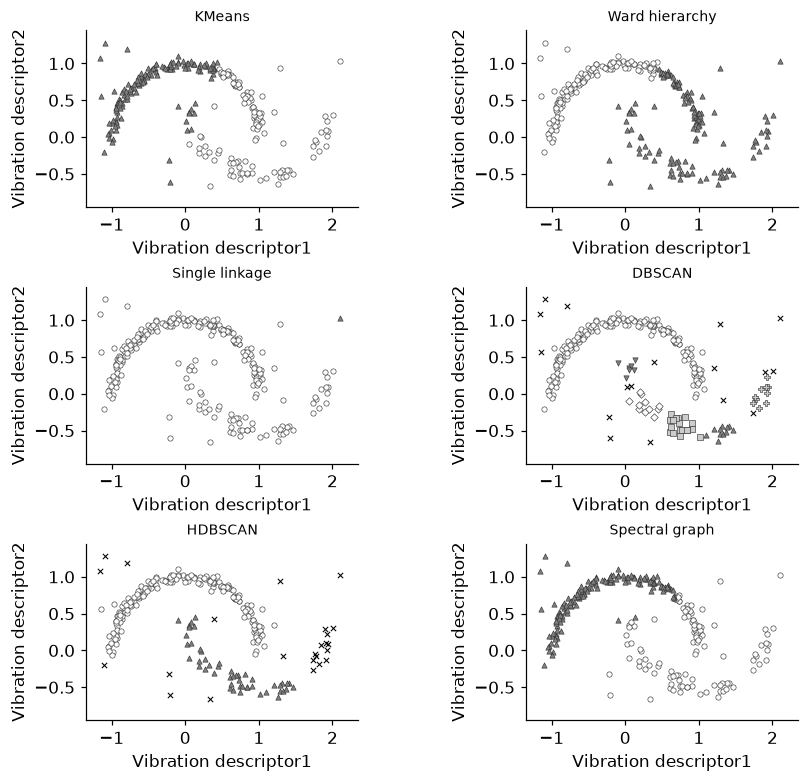

In [2]:
from sklearn.cluster import KMeans,AgglomerativeClustering,DBSCAN,HDBSCAN,SpectralClustering
from sklearn.metrics import adjusted_rand_score
from scipy.spatial.distance import cdist
angle_a=rng.uniform(0,np.pi,180);angle_b=rng.uniform(0,np.pi,60);a=np.column_stack([np.cos(angle_a),np.sin(angle_a)])+rng.normal(0,.04,(180,2));b=np.column_stack([1-np.cos(angle_b),.5-np.sin(angle_b)])+rng.normal(0,.08,(60,2));background=rng.uniform([-1.2,-.8],[2.2,1.3],(20,2));X=np.vstack([a,b,background]);truth=np.r_[np.zeros(180,int),np.ones(60,int),np.full(20,-1)];affinity=np.exp(-8*cdist(X,X,'sqeuclidean'));np.testing.assert_allclose(affinity,affinity.T);assert np.all(affinity>0)
models={'KMeans':KMeans(2,n_init=20,random_state=SEED),'Ward hierarchy':AgglomerativeClustering(2,linkage='ward'),'Single linkage':AgglomerativeClustering(2,linkage='single'),'DBSCAN':DBSCAN(eps=.18,min_samples=7),'HDBSCAN':HDBSCAN(min_cluster_size=20,min_samples=7,n_jobs=1,copy=True),'Spectral graph':SpectralClustering(2,affinity='precomputed',assign_labels='cluster_qr',random_state=SEED)};labels={name:fit.fit_predict(affinity if name=='Spectral graph' else X) for name,fit in models.items()};rows=[]
for name,label in labels.items():
 ids=set(label);rows.append({'method':name,'clusters_excluding_noise':len(ids-{-1}),'noise_rows':int(np.sum(label==-1)),'all_record_generator_ARI':float(adjusted_rand_score(truth,label)),'known_moon_record_ARI':float(adjusted_rand_score(truth[:240],label[:240]))})
RESULTS['partitions']=rows;RESULTS['analysis_contract']={'dense_moon':180,'sparse_moon':60,'uniform_background':20,'transductive_records':260,'geometry':'declared original dimensionless descriptors','spectral_RBF_gamma':8,'HDBSCAN_min_samples_includes_self':True,'new_query_predictor_claimed':False}
def plot_partition(ax,label,title):
 for group in sorted(set(label)):
  mask=label==group
  if group==-1:ax.scatter(*X[mask].T,marker='x',color='black',s=12,linewidths=.7)
  else:ax.scatter(*X[mask].T,marker=['o','^','s','D','v','P'][group%6],facecolors=['white','.5','.8'][group%3],edgecolors='.2',s=12,linewidths=.4)
 ax.set(title=title,xlabel='Vibration descriptor1',ylabel='Vibration descriptor2',xlim=(-1.35,2.35),ylim=(-.95,1.45),aspect='equal')
fig,axes=plt.subplots(3,2,figsize=(8,7))
for ax,(name,label) in zip(axes.flat,labels.items()):plot_partition(ax,label,name)
plt.show()


<a id="boundaries"></a>
## Density parameters and boundary records remain choices

Vary DBSCANeps[.12,.18,.30] and HDBSCANmin_cluster_size[12,20,40] one at a time with the other controls fixed. Report cluster counts and noise fractions rather than selecting the most attractive external label match. Twenty prescribed sensor-jitter reruns (noiseSD.025) audit DBSCAN at the fixed base setting. ARI compares complete partitions without relying on arbitrary label identities. Per-record clustered frequency reports how often a record avoids the noise label; it is not a membership posterior. Keep counts for the eight most boundary-sensitive original IDs and the number of reruns. Density connectivity can change abruptly as a bridge appears, and noise labeling can discard sparse but legitimate regimes.


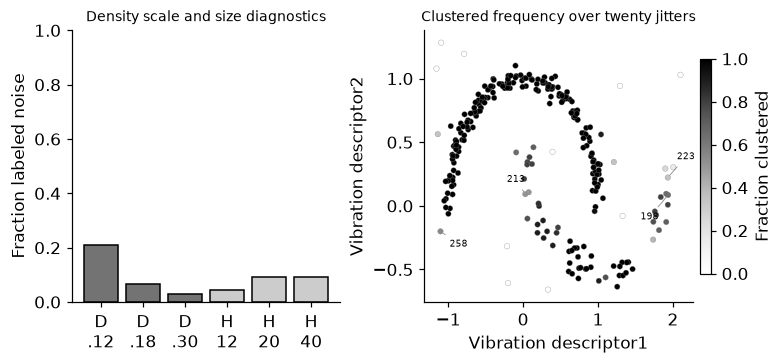

In [3]:
parameter_rows=[]
for eps in [.12,.18,.30]:
 label=DBSCAN(eps=eps,min_samples=7).fit_predict(X);parameter_rows.append({'method':'DBSCAN','parameter':eps,'clusters':len(set(label)-{-1}),'noise_fraction':float(np.mean(label==-1))})
for size in [12,20,40]:
 label=HDBSCAN(min_cluster_size=size,min_samples=7,n_jobs=1,copy=True).fit_predict(X);parameter_rows.append({'method':'HDBSCAN','parameter':size,'clusters':len(set(label)-{-1}),'noise_fraction':float(np.mean(label==-1))})
perturbed=[];ari=[]
for _ in range(20):
 label=DBSCAN(eps=.18,min_samples=7).fit_predict(X+rng.normal(0,.025,X.shape));perturbed.append(label!=-1);ari.append(float(adjusted_rand_score(labels['DBSCAN'],label)))
frequency=np.mean(perturbed,axis=0);assert np.all((frequency>=0)&(frequency<=1));boundary=np.argsort(np.abs(frequency-.5))[:8];RESULTS['parameter_diagnostics']=parameter_rows;RESULTS['sensor_jitter']={'reruns':20,'coordinate_noise_SD':.025,'partition_ARI_min':min(ari),'partition_ARI_mean':float(np.mean(ari)),'boundary_records':[{'original_id':int(i),'clustered_count':int(round(frequency[i]*20)),'reruns':20,'clustered_fraction':float(frequency[i]),'background_generator_annotation':bool(truth[i]==-1)} for i in boundary]};assert sum(v['noise_rows'] for v in rows)>=0
fig,axes=plt.subplots(1,2,figsize=(7,3.2));pos=np.arange(6);axes[0].bar(pos,[r['noise_fraction'] for r in parameter_rows],color=['.45']*3+['.8']*3,edgecolor='black');axes[0].set(xticks=pos,xticklabels=['D\n.12','D\n.18','D\n.30','H\n12','H\n20','H\n40'],ylabel='Fraction labeled noise',ylim=(0,1),title='Density scale and size diagnostics');scatter=axes[1].scatter(*X.T,c=frequency,cmap='Greys',vmin=0,vmax=1,s=13,edgecolors='.5',linewidths=.2)
for i,offset in zip(boundary[::2],[(-12,8),(6,-10),(-18,-16),(6,12)]):axes[1].annotate(str(i),X[i],xytext=offset,textcoords='offset points',fontsize=6,arrowprops=dict(arrowstyle='-',color='.5',lw=.5))
axes[1].set(xlabel='Vibration descriptor1',ylabel='Vibration descriptor2',title='Clustered frequency over twenty jitters');fig.colorbar(scatter,ax=axes[1],fraction=.04,pad=.02,label='Fraction clustered');plt.show()


In [4]:
summary={'example_id':'code_094','seed':SEED,'versions':VERSIONS,'hardware':platform.system()+' '+platform.machine()+' CPU','concepts_demonstrated':['same-point centroid hierarchy density and spectral partitions', 'native HDBSCAN density hierarchy', 'noise labels and scale controls', 'boundary sensitivity without comparing arbitrary label IDs'],'results':RESULTS,'elapsed_seconds':round(time.perf_counter()-START,3)}
print('EXECUTION_SUMMARY_JSON:'+json.dumps(summary,sort_keys=True,allow_nan=False))


EXECUTION_SUMMARY_JSON:{"concepts_demonstrated": ["same-point centroid hierarchy density and spectral partitions", "native HDBSCAN density hierarchy", "noise labels and scale controls", "boundary sensitivity without comparing arbitrary label IDs"], "elapsed_seconds": 0.482, "example_id": "code_094", "hardware": "Darwin arm64 CPU", "results": {"analysis_contract": {"HDBSCAN_min_samples_includes_self": true, "dense_moon": 180, "geometry": "declared original dimensionless descriptors", "new_query_predictor_claimed": false, "sparse_moon": 60, "spectral_RBF_gamma": 8, "transductive_records": 260, "uniform_background": 20}, "parameter_diagnostics": [{"clusters": 3, "method": "DBSCAN", "noise_fraction": 0.21153846153846154, "parameter": 0.12}, {"clusters": 6, "method": "DBSCAN", "noise_fraction": 0.06538461538461539, "parameter": 0.18}, {"clusters": 3, "method": "DBSCAN", "noise_fraction": 0.03076923076923077, "parameter": 0.3}, {"clusters": 3, "method": "HDBSCAN", "noise_fraction": 0.0423076